# Analysis of Student Attendance vs Academic Performance
**Course:** Data Analytics Using Python (CSL-0312) | **Program:** B.Tech. CSE (AI & ML), Sem III, Section F

**Team:** P. Chethan (BETN1A125194), G. Nandini (BETN1A125164), J. Durgeshwar (BETN1A125167)
**Faculty Mentor:** Dr. Sanjay Jain

**Dataset:** `students_500_dataset_updated.csv`

This notebook reproduces every table, number and figure (Figures 1-9) used in the PBL report. Run the cells from top to bottom.

## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings("ignore")

# small display settings so tables print neatly
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 150)

## 2. Load the dataset
In Colab, upload the CSV first (left sidebar > Files > Upload) or run the cell below to pick it from your computer.

In [ ]:
import os
if not os.path.exists("/content/students_500_dataset_with_names.csv.xls"):
    from google.colab import files
    uploaded = files.upload()
    name = list(uploaded.keys())[0]
    os.rename(name, "/content/students_500_dataset_with_names.csv.xls")

Saving students_500_dataset_with_names.csv.xls to students_500_dataset_with_names.csv (1).xls


In [ ]:
df = pd.read_csv("/content/students_500_dataset_with_names.csv.xls")
df.head()

,index,Name,Attendance,InternalMarks,FinalMarks,StudyHours,AssignmentScore,PreviousSemesterScore
0,1,Sneha Singh,84.0,81.9,89.5,9.0,58.9,53.7
1,2,Sakshi Pandey,76.3,96.6,94.5,8.5,49.5,66.7
2,3,Kavya Tiwari,85.8,47.0,58.1,6.6,24.8,33.5
3,4,Charan Pillai,96.3,76.4,74.9,7.0,44.2,57.6
4,5,Aditi Bansal,75.2,58.2,54.8,7.2,36.7,25.0


## 3. Data cleaning & preprocessing

In [ ]:
print("Shape (rows, columns):", df.shape)
print("\n")
print("Columns:", list(df.columns))
print("\n")
print("Data types:")
print(df.dtypes)

Shape (rows, columns): (500, 11)


Columns: ['index', 'Name', 'Attendance', 'InternalMarks', 'FinalMarks', 'StudyHours', 'AssignmentScore', 'PreviousSemesterScore', 'Attendance_Group', 'Attendance_Band', 'Marks_Band']


Data types:
index                       int64
Name                       object
Attendance                float64
InternalMarks             float64
FinalMarks                float64
StudyHours                float64
AssignmentScore           float64
PreviousSemesterScore     float64
Attendance_Group         category
Attendance_Band          category
Marks_Band                 object
dtype: object


In [ ]:
# missing values and duplicates
print("Missing values per column:")
print(df.isna().sum())
print("\n")
print("Total missing values:", df.isna().sum().sum())
print("\n")
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
index                    0
Name                     0
Attendance               0
InternalMarks            0
FinalMarks               0
StudyHours               0
AssignmentScore          0
PreviousSemesterScore    0
Attendance_Group         0
Attendance_Band          0
Marks_Band               0
dtype: int64


Total missing values: 0


Duplicate rows: 0


No missing values and no duplicate rows, so no imputation or removal is needed.

The raw file has 8 columns. The report's ninth column, **Attendance_Group**, is created here from the Attendance percentage:
- **Low**: attendance below 70
- **Medium**: attendance from 70 up to (but not including) 85
- **High**: attendance 85 and above

In [ ]:
def make_group(a):
    if a < 70:
        return "Low"
    elif a < 85:
        return "Medium"
    else:
        return "High"

df["Attendance_Group"] = df["Attendance"].apply(make_group)

# keep the groups in a sensible order for tables and charts
order = ["Low", "Medium", "High"]
df["Attendance_Group"] = pd.Categorical(df["Attendance_Group"], categories=order, ordered=True)

print("Shape after adding Attendance_Group:", df.shape)
print(df["Attendance_Group"].value_counts().reindex(order))

Shape after adding Attendance_Group: (500, 9)
Attendance_Group
Low       130
Medium    233
High      137
Name: count, dtype: int64


In [ ]:
# numeric columns used for statistics (index and Name are only identifiers)
num_cols = ["Attendance", "InternalMarks", "FinalMarks",
            "StudyHours", "AssignmentScore", "PreviousSemesterScore"]

# Representative code from the report
r, p = stats.pearsonr(df["Attendance"], df["FinalMarks"])
print("Pearson r (Attendance, FinalMarks):", round(r, 3), " p =", p)

Pearson r (Attendance, FinalMarks): 0.324  p = 1.174146886479224e-13


## 4. Exploratory Data Analysis (EDA)

In [ ]:
summary = pd.DataFrame({
    "Mean":   df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "SD":     df[num_cols].std(),
    "Min":    df[num_cols].min(),
    "Max":    df[num_cols].max()
}).round(2)
summary

,Mean,Median,SD,Min,Max
Attendance,77.90,78.20,11.27,45.0,100.0
InternalMarks,68.40,68.40,14.45,30.0,100.0
FinalMarks,71.46,71.55,12.53,37.6,100.0
StudyHours,6.84,6.80,1.34,2.7,10.0
AssignmentScore,41.60,41.20,11.41,20.0,74.9
PreviousSemesterScore,53.23,53.35,13.84,25.0,89.2


In [ ]:
print("Attendance  mean = %.2f (SD %.2f)" % (df["Attendance"].mean(), df["Attendance"].std()))
print("FinalMarks  mean = %.2f (SD %.2f; median %.2f)" % (df["FinalMarks"].mean(),
                                                           df["FinalMarks"].std(),
                                                           df["FinalMarks"].median()))

Attendance  mean = 77.90 (SD 11.27)
FinalMarks  mean = 71.46 (SD 12.53; median 71.55)


In [ ]:
# group-wise summary
group_table = df.groupby("Attendance_Group").agg(
    n=("FinalMarks", "size"),
    mean_attendance=("Attendance", "mean"),
    mean_final_marks=("FinalMarks", "mean"),
    sd_final_marks=("FinalMarks", "std")
).round(2)
group_table

,n,mean_attendance,mean_final_marks,sd_final_marks
Attendance_Group,,,,
Low,130,63.70,66.38,12.40
Medium,233,77.69,71.06,11.76
High,137,91.74,76.96,11.81


In [ ]:
# skewness check (the report asks for this to be verified)
print("Skewness of each numeric variable:")
print(df[num_cols].skew().round(2))
print()
print("All values lie between -0.2 and +0.2?", bool((df[num_cols].skew().abs() <= 0.2).all()))

Skewness of each numeric variable:
Attendance              -0.04
InternalMarks           -0.01
FinalMarks              -0.04
StudyHours              -0.07
AssignmentScore          0.20
PreviousSemesterScore   -0.02
dtype: float64

All values lie between -0.2 and +0.2? True


All six skewness values lie within +/-0.2 (AssignmentScore is right at the edge, 0.1998), so the variables are roughly symmetric and mean and median are close.

## 5. Data visualization

In [ ]:
# Figures 1-4 use the plain matplotlib look
plt.style.use("default")
group_colors = {"Low": "#1f77b4", "Medium": "#ff7f0e", "High": "#2ca02c"}

### Figure 1. Attendance distribution

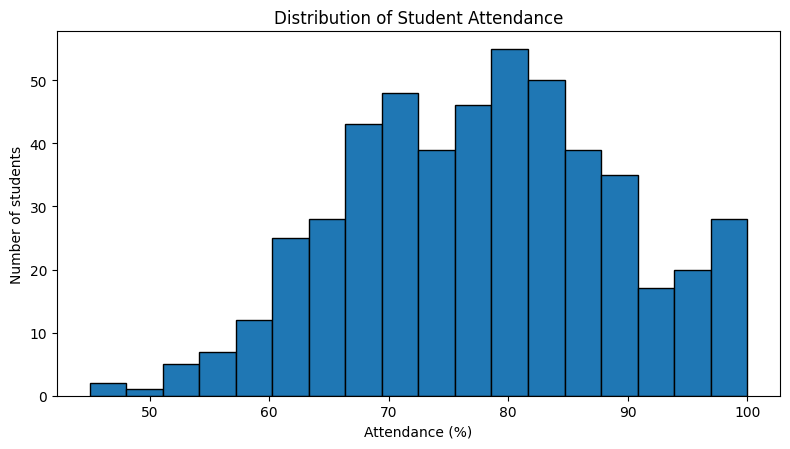

In [ ]:
plt.figure(figsize=(8, 4.6))
plt.hist(df["Attendance"], bins=18, color="#1f77b4", edgecolor="black")
plt.title("Distribution of Student Attendance")
plt.xlabel("Attendance (%)")
plt.ylabel("Number of students")
plt.grid(False)
plt.tight_layout()
plt.show()

**Observation:** roughly bell-shaped, peaking at about 80%. Most students are between 60% and 90%, only a few are below 55%, and there is a small rise at the 100% end.

### Figure 2. Attendance vs FinalMarks

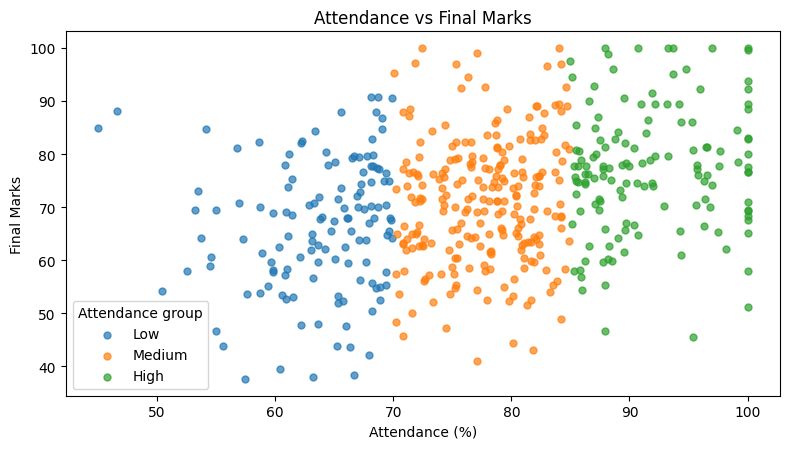

Pearson r = 0.324


In [ ]:
plt.figure(figsize=(8, 4.6))
for g in order:
    sub = df[df["Attendance_Group"] == g]
    plt.scatter(sub["Attendance"], sub["FinalMarks"], alpha=0.7, s=25,
                color=group_colors[g], label=g)
plt.title("Attendance vs Final Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Final Marks")
plt.legend(title="Attendance group", loc="lower left")
plt.grid(False)
plt.tight_layout()
plt.show()

print("Pearson r =", round(r, 3))

**Observation:** points drift upward from left to right (r = 0.324), but the spread is wide, so students with similar attendance can score very differently.

### Figure 3. Final marks by attendance group

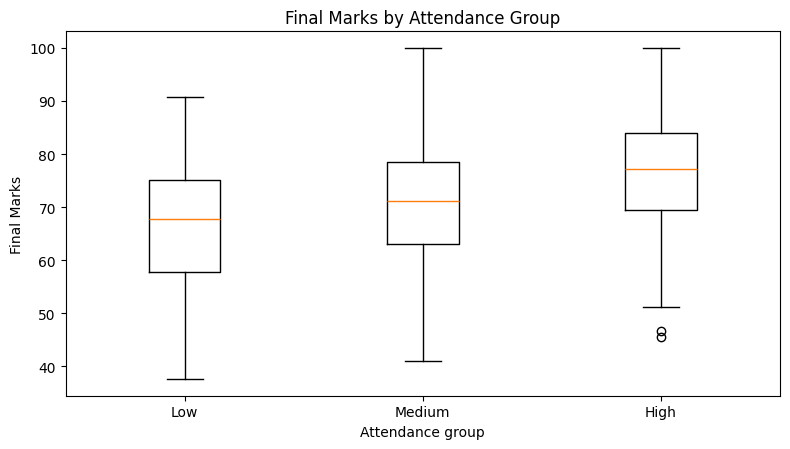

Median final marks by group:
Attendance_Group
Low       67.7
Medium    71.1
High      77.2
Name: FinalMarks, dtype: float64


In [ ]:
plt.figure(figsize=(8, 4.6))
data_to_plot = [df.loc[df["Attendance_Group"] == g, "FinalMarks"] for g in order]
plt.boxplot(data_to_plot, medianprops={"color": "#ff7f0e"})
plt.xticks([1, 2, 3], order)
plt.title("Final Marks by Attendance Group")
plt.xlabel("Attendance group")
plt.ylabel("Final Marks")
plt.grid(False)
plt.tight_layout()
plt.show()

print("Median final marks by group:")
print(df.groupby("Attendance_Group")["FinalMarks"].median())

**Observation:** the median rises from 67.70 (Low) to 71.10 (Medium) to 77.20 (High). The boxes overlap, so high attendance does not guarantee high marks. Two low outliers (about 46) appear in the High group.

### Figure 4. Correlation heatmap

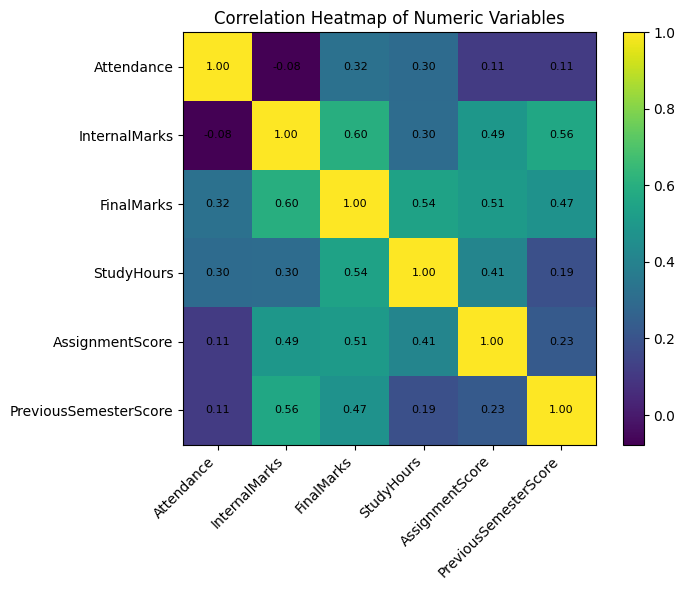

In [ ]:
corr = df[num_cols].corr()

plt.figure(figsize=(7.5, 6))
plt.imshow(corr, cmap="viridis")
plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
plt.yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        plt.text(j, i, "%.2f" % corr.iloc[i, j], ha="center", va="center",
                 fontsize=8, color="black")
plt.title("Correlation Heatmap of Numeric Variables")
plt.grid(False)
plt.tight_layout()
plt.show()

In [ ]:
corr.round(2)

,Attendance,InternalMarks,FinalMarks,StudyHours,AssignmentScore,PreviousSemesterScore
Attendance,1.00,-0.08,0.32,0.30,0.11,0.11
InternalMarks,-0.08,1.00,0.60,0.30,0.49,0.56
FinalMarks,0.32,0.60,1.00,0.54,0.51,0.47
StudyHours,0.30,0.30,0.54,1.00,0.41,0.19
AssignmentScore,0.11,0.49,0.51,0.41,1.00,0.23
PreviousSemesterScore,0.11,0.56,0.47,0.19,0.23,1.00


**Observation:** InternalMarks (0.60), StudyHours (0.54), AssignmentScore (0.51) and PreviousSemesterScore (0.47) link more strongly with FinalMarks than Attendance (0.32). Attendance is linked with StudyHours (0.30) but not with InternalMarks (-0.08). Correlation does not prove causation.

### Figure 5. Mean scores by attendance group

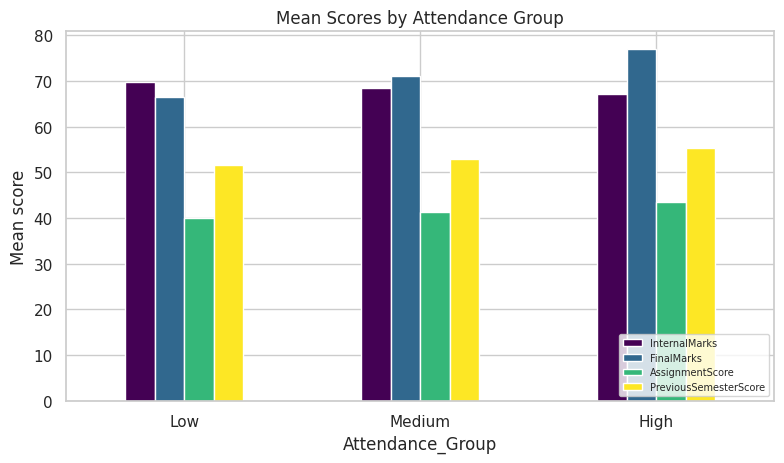

,InternalMarks,FinalMarks,AssignmentScore,PreviousSemesterScore
Attendance_Group,,,,
Low,69.81,66.38,39.99,51.49
Medium,68.32,71.06,41.34,52.96
High,67.20,76.96,43.55,55.34


In [ ]:
# Figures 5-9 use the seaborn look
sns.set_theme(style="whitegrid")

mean_scores = df.groupby("Attendance_Group")[["InternalMarks", "FinalMarks",
                                              "AssignmentScore", "PreviousSemesterScore"]].mean()

ax = mean_scores.plot(kind="bar", figsize=(8, 4.8), colormap="viridis", rot=0)
ax.set_title("Mean Scores by Attendance Group")
ax.set_xlabel("Attendance_Group")
ax.set_ylabel("Mean score")
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

mean_scores.round(2)

**Observation:** mean FinalMarks rise from 66.38 (Low) to 71.06 (Medium) to 76.96 (High). AssignmentScore and PreviousSemesterScore also rise, while InternalMarks stays almost flat (about 69.8, 68.3 and 67.2).

### Figure 6. Correlation of each variable with FinalMarks

Attendance               0.324
PreviousSemesterScore    0.472
AssignmentScore          0.510
StudyHours               0.542
InternalMarks            0.600
Name: FinalMarks, dtype: float64


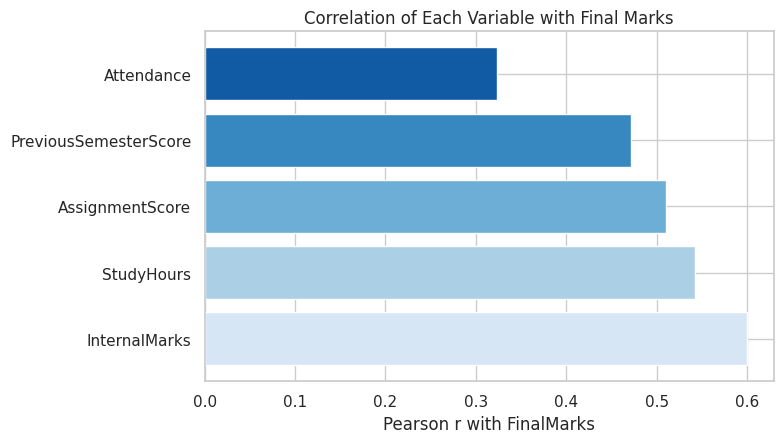

In [ ]:
corr_final = df[num_cols].corr()["FinalMarks"].drop("FinalMarks").sort_values()
print(corr_final.round(3))

plt.figure(figsize=(8, 4.6))
colors = sns.color_palette("Blues_r", len(corr_final))[::-1]
# Attendance (smallest r) is drawn at the top, InternalMarks (largest r) at the bottom
plt.barh(corr_final.index[::-1], corr_final.values[::-1], color=colors)
plt.title("Correlation of Each Variable with Final Marks")
plt.xlabel("Pearson r with FinalMarks")
plt.tight_layout()
plt.show()

**Observation:** InternalMarks (0.600) has the strongest link, then StudyHours (0.542), AssignmentScore (0.510) and PreviousSemesterScore (0.472). Attendance (0.324) ranks last.

### Figure 7. Mean FinalMarks by attendance band

Attendance_Band
Below 60    64.1
60-69       67.0
70-79       70.8
80-89       72.9
90-100      79.0
Name: FinalMarks, dtype: float64


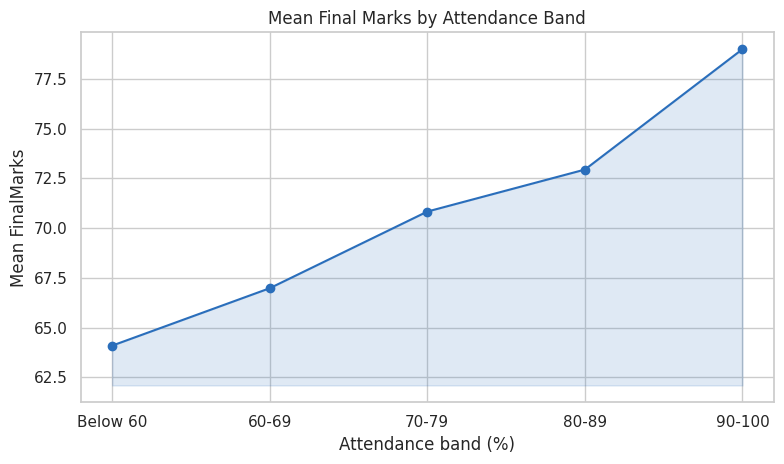

In [ ]:
bins = [0, 60, 70, 80, 90, 100.01]
labels = ["Below 60", "60-69", "70-79", "80-89", "90-100"]
df["Attendance_Band"] = pd.cut(df["Attendance"], bins=bins, labels=labels, right=False)

band_mean = df.groupby("Attendance_Band")["FinalMarks"].mean()
print(band_mean.round(1))

plt.figure(figsize=(8, 4.8))
plt.plot(labels, band_mean.values, marker="o", color="#2a6ebb")
plt.fill_between(labels, band_mean.values, band_mean.values.min() - 2,
                 color="#2a6ebb", alpha=0.15)
plt.title("Mean Final Marks by Attendance Band")
plt.xlabel("Attendance band (%)")
plt.ylabel("Mean FinalMarks")
plt.tight_layout()
plt.show()

**Observation:** mean final marks increase at every step: 64.1, 67.0, 70.8, 72.9 and 79.0. The sharpest rise is between the 80-89% and 90-100% bands.

### Figure 8. Attendance vs FinalMarks (bubble size = StudyHours)

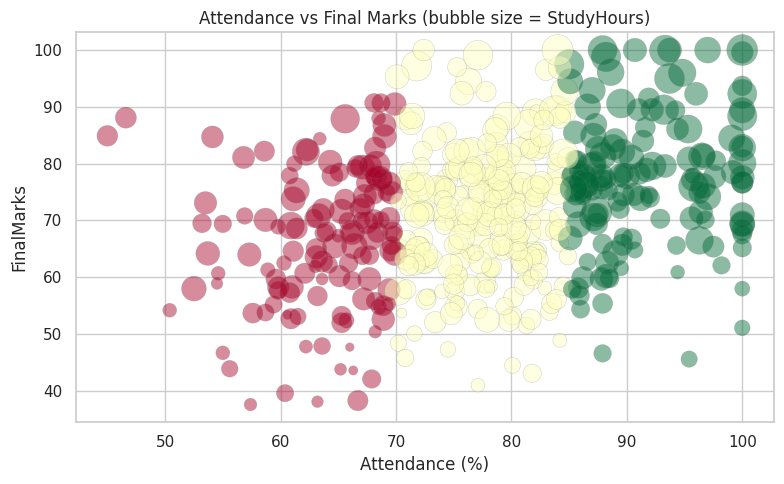

Mean study hours by group:
Attendance_Group
Low       6.33
Medium    6.76
High      7.46
Name: StudyHours, dtype: float64


In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Attendance"], df["FinalMarks"],
            s=df["StudyHours"] ** 2 * 5,
            c=df["Attendance_Group"].cat.codes, cmap="RdYlGn",
            alpha=0.45, edgecolors="grey", linewidths=0.3)
plt.title("Attendance vs Final Marks (bubble size = StudyHours)")
plt.xlabel("Attendance (%)")
plt.ylabel("FinalMarks")
plt.tight_layout()
plt.show()

print("Mean study hours by group:")
print(df.groupby("Attendance_Group")["StudyHours"].mean().round(2))

**Observation:** high-attendance students (green) tend to have bigger bubbles and higher marks. Mean study hours are 6.33, 6.76 and 7.46 for Low, Medium and High.

### Figure 9. Final marks bands within each attendance group

Marks_Band        Below 60  60-74  75 and above
Attendance_Group                               
Low                   31.5   43.1          25.4
Medium                17.6   43.8          38.6
High                   8.8   32.1          59.1


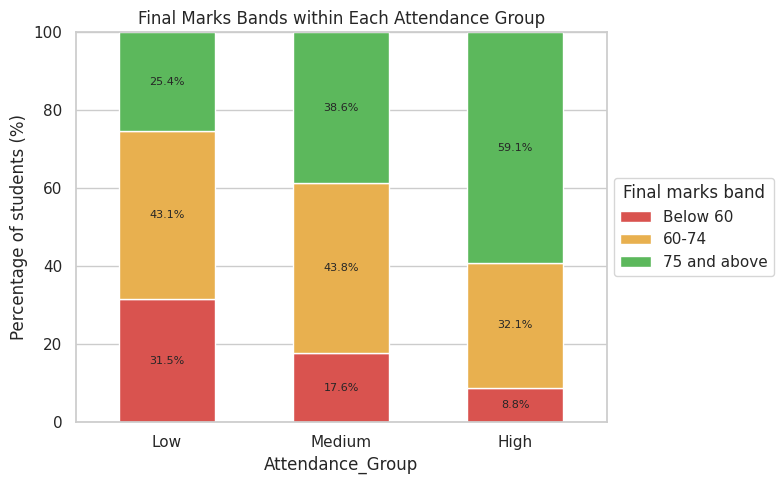

In [ ]:
def marks_band(m):
    if m < 60:
        return "Below 60"
    elif m < 75:
        return "60-74"
    else:
        return "75 and above"

df["Marks_Band"] = df["FinalMarks"].apply(marks_band)

band_pct = pd.crosstab(df["Attendance_Group"], df["Marks_Band"], normalize="index") * 100
band_pct = band_pct[["Below 60", "60-74", "75 and above"]]
print(band_pct.round(1))

band_colors = ["#d9534f", "#e8b04f", "#5cb85c"]
ax = band_pct.plot(kind="bar", stacked=True, figsize=(8, 5), color=band_colors,
                   rot=0, width=0.55, edgecolor="white")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", fontsize=8)
ax.set_title("Final Marks Bands within Each Attendance Group")
ax.set_xlabel("Attendance_Group")
ax.set_ylabel("Percentage of students (%)")
ax.set_ylim(0, 100)
ax.legend(title="Final marks band", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

**Observation:** the share scoring 75 or above rises from 25.4% (Low) to 38.6% (Medium) to 59.1% (High), while the share below 60 falls from 31.5% to 17.6% to 8.8%.

## 6. Statistical analysis

### Correlation tests (Table 5)

In [ ]:
# Attendance vs FinalMarks
r1, p1 = stats.pearsonr(df["Attendance"], df["FinalMarks"])
print("Attendance vs FinalMarks:     r = %.3f, p = %.1e" % (r1, p1))

# Attendance vs InternalMarks
r2, p2 = stats.pearsonr(df["Attendance"], df["InternalMarks"])
print("Attendance vs InternalMarks:  r = %.3f, p = %.3f" % (r2, p2))

# numpy corrcoef and z-score check
r_np = np.corrcoef(df["Attendance"], df["FinalMarks"])[0, 1]
z_att = (df["Attendance"] - df["Attendance"].mean()) / df["Attendance"].std()
z_fin = (df["FinalMarks"] - df["FinalMarks"].mean()) / df["FinalMarks"].std()
r_z = np.corrcoef(z_att, z_fin)[0, 1]
print("NumPy corrcoef r = %.3f | z-score r = %.3f" % (r_np, r_z))

# coefficient of determination
print("r squared = %.3f^2 = %.3f" % (r1, r1 ** 2))

Attendance vs FinalMarks:     r = 0.324, p = 1.2e-13
Attendance vs InternalMarks:  r = -0.078, p = 0.083
NumPy corrcoef r = 0.324 | z-score r = 0.324
r squared = 0.324^2 = 0.105


### One-way ANOVA across attendance groups (Table 6)

H0: mean FinalMarks are equal for Low, Medium and High groups. H1: at least one group mean differs.

In [ ]:
low  = df.loc[df["Attendance_Group"] == "Low", "FinalMarks"]
med  = df.loc[df["Attendance_Group"] == "Medium", "FinalMarks"]
high = df.loc[df["Attendance_Group"] == "High", "FinalMarks"]

F, p_anova = stats.f_oneway(low, med, high)
df_between = 3 - 1
df_within = len(df) - 3
print("ANOVA FinalMarks:    F(%d, %d) = %.2f, p = %.1e" % (df_between, df_within, F, p_anova))
if p_anova < 0.05:
    print("Reject H0 at 5%: at least one mean differs")

# same test on InternalMarks
F2, p2_anova = stats.f_oneway(*[df.loc[df["Attendance_Group"] == g, "InternalMarks"] for g in order])
print("ANOVA InternalMarks: F = %.2f, p = %.3f" % (F2, p2_anova))
if p2_anova >= 0.05:
    print("Fail to reject H0")

In [ ]:
# group mean differences
print("Medium - Low  : %.2f - %.2f = %.2f" % (med.mean(), low.mean(), med.mean() - low.mean()))
print("High - Medium : %.2f - %.2f = %.2f" % (high.mean(), med.mean(), high.mean() - med.mean()))
print("High - Low    : %.2f - %.2f = %.2f" % (high.mean(), low.mean(), high.mean() - low.mean()))

# attendance >= 75 vs < 75
above = df.loc[df["Attendance"] >= 75, "FinalMarks"]
below = df.loc[df["Attendance"] < 75, "FinalMarks"]
print()
print("Attendance >=75%% vs <75%%: %.2f vs %.2f; n=%d vs %d" % (above.mean(), below.mean(), len(above), len(below)))
print("Difference: about %.1f marks higher in the >=75%% group" % (above.mean() - below.mean()))

ANOVA only says that at least one group mean differs; it does not say which pairs differ. A post-hoc test (like Tukey HSD) would be needed for pairwise conclusions.

## 7. Conclusion

- Attendance has a **positive, moderate** association with final marks (r = 0.324, r² = 0.105).
- Mean final marks rise from Low (66.38) to Medium (71.06) to High (76.96) attendance, and ANOVA confirms the difference is significant (F(2, 497) = 26.43, p ≈ 1.2e-11).
- InternalMarks, StudyHours and AssignmentScore are more strongly tied to FinalMarks than attendance.
- The data are observational, so these results show association, not cause.

**Future scope:** use a larger, verified dataset, check ANOVA assumptions, run post-hoc tests and try multiple regression.